## Import Packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras._tf_keras.keras import layers
from keras._tf_keras.keras.models import Sequential
from keras._tf_keras.keras.layers import Dense,Flatten,Dropout,BatchNormalization
from keras._tf_keras.keras.losses import SparseCategoricalCrossentropy
from keras._tf_keras.keras.callbacks import EarlyStopping

## Set Constant Values

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 224
CHANNELS = 3

## Download or load the dataset 

In [3]:
training = "Data/LumpySkin_Dataset/train/"
testing = "Data/LumpySkin_Dataset/test/"

## Image Preprocessing

### Create Dataset for train,test,validation

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
  training,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 1009 files belonging to 2 classes.
Using 808 files for training.


In [5]:
test_ds = tf.keras.utils.image_dataset_from_directory(
  testing,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 440 files belonging to 2 classes.
Using 352 files for training.


In [6]:
val_ds = tf.keras.utils.image_dataset_from_directory(
  training,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(IMAGE_SIZE, IMAGE_SIZE),
  batch_size=BATCH_SIZE)

Found 1009 files belonging to 2 classes.
Using 201 files for validation.


In [7]:
class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)

['Lumpy_Skin', 'Normal_Skin']


## Visualize the data

In [8]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 224, 224, 3)
(32,)


## Configure the dataset for performance

In [9]:
trian_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

## Standardize the data

In [10]:
normalization_layer = layers.Rescaling(1./255)

In [11]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.0 1.0


## Resize and Rescale

In [12]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(0.1 / 256)
])

## Data Augmentation

In [13]:
data_augmentation  = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.2)
])

In [14]:
train_ds = train_ds.map(
    lambda x,y: (data_augmentation(x, training=True),y),
).prefetch(buffer_size = tf.data.AUTOTUNE)

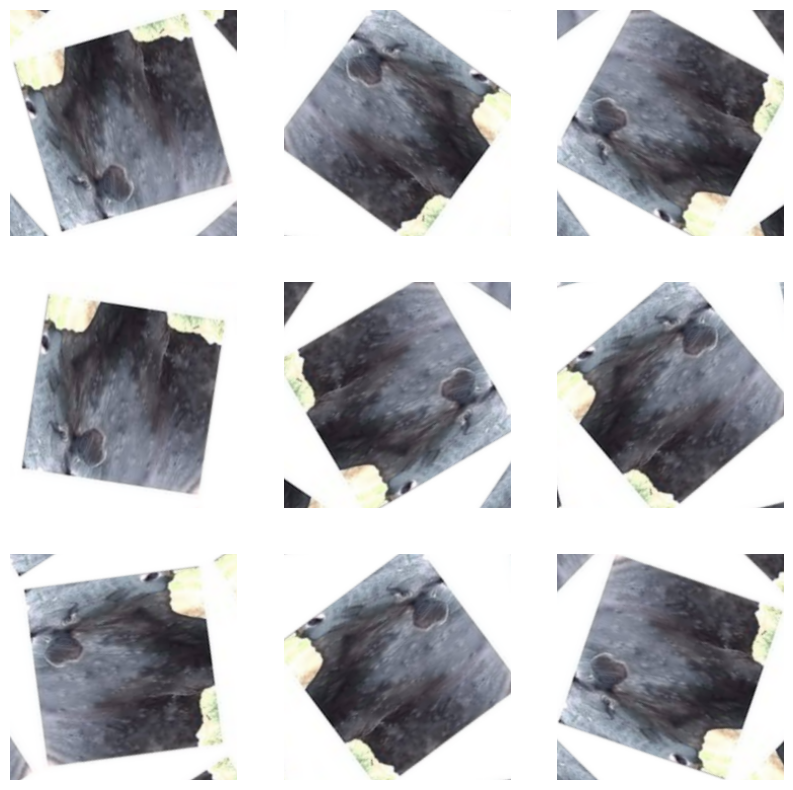

In [15]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

Define the EarlyStopping callback

In [16]:
early_stopping = EarlyStopping(
    monitor='val_loss',  # or 'val_accuracy' depending on your goal
    patience=3,          # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True,  # Restore model weights from the epoch with the best value of the monitored quantity
    verbose=1
)

# CNN Model Implementation

Model Layering

In [17]:
model = Sequential([
  data_augmentation,
  layers.Rescaling(1./255),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(128, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Dropout(0.2),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes, activation='softmax')
])

Compile the model

In [18]:
model.compile(
    optimizer='adam',
    loss= "sparse_categorical_crossentropy",
    metrics=['accuracy']
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,309,090 (12.62 MB)

 Trainable params: 3,309,090 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [20]:
epochs = 50
history = model.fit(
  train_ds,
  epochs=epochs, 
  validation_data=val_ds,
  batch_size=BATCH_SIZE
)

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 570ms/step - accuracy: 0.6602 - loss: 0.5926 - val_accuracy: 0.6816 - val_loss: 0.7091
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 585ms/step - accuracy: 0.7170 - loss: 0.5313 - val_accuracy: 0.7114 - val_loss: 0.7086
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 610ms/step - accuracy: 0.7394 - loss: 0.5525 - val_accuracy: 0.8010 - val_loss: 0.4646
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 15s 574ms/step - accuracy: 0.8237 - loss: 0.4492 - val_accuracy: 0.7811 - val_loss: 0.4636
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 596ms/step - accuracy: 0.8186 - loss: 0.3899 - val_accuracy: 0.8010 - val_loss: 0.4431
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 595ms/step - accuracy: 0.8248 - loss: 0.4294 - val_accuracy: 0.8109 - val_loss: 0.4589
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 591ms/step - accuracy: 0.8144 - loss: 0.4108 - val_accuracy: 0.8159 - val_loss: 0.4289
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 16s 596ms/step - accuracy: 0.8302 - loss: 0.3848 - val_accu

Evaluate the model

In [21]:
model.evaluate(test_ds)

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 130ms/step - accuracy: 0.8735 - loss: 0.3088


[0.3381912112236023, 0.8636363744735718]

# Visualize training results

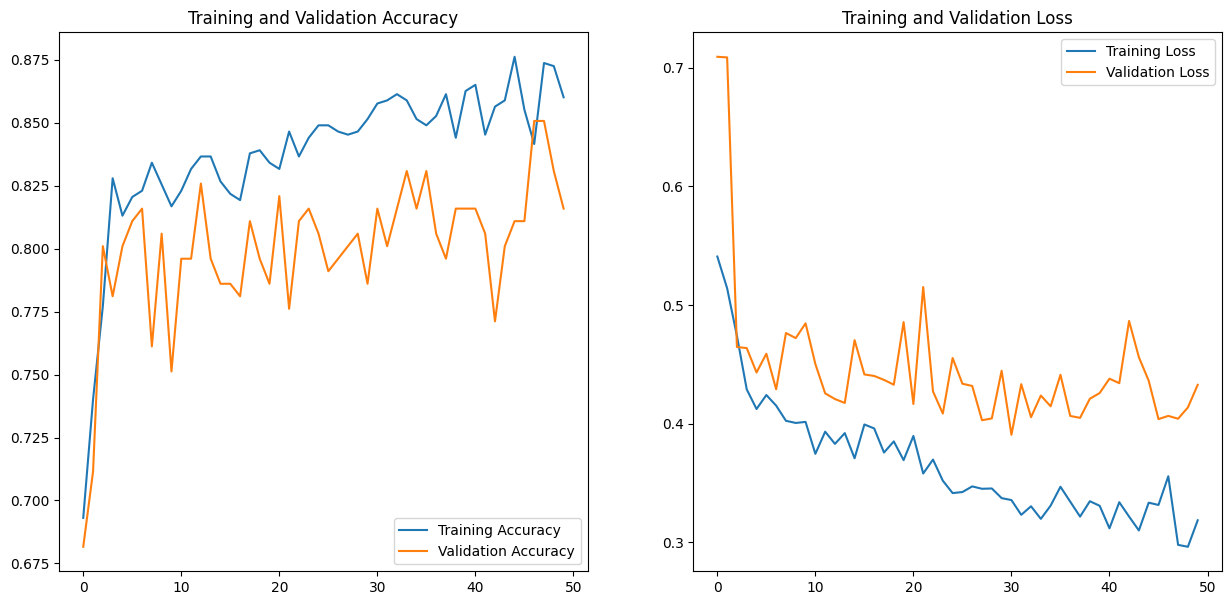

In [22]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

### Save the model

In [23]:
model.save('Model CNN.keras')

# ResNet Model Implementation

Import the base model

In [24]:
from keras._tf_keras.keras.applications.resnet50 import ResNet50

Create a base model

In [25]:
conv_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(IMAGE_SIZE,IMAGE_SIZE,CHANNELS)
)
conv_base.trainable = False

Add Connected layers to VGG19 Base

In [26]:
model_res = Sequential()
resize_and_rescale
model_res.add(conv_base)
model_res.add(Flatten())
model_res.add(Dense(256,activation='relu'))
model_res.add(Dropout(0.5))
model_res.add(BatchNormalization())
model_res.add(Dense(num_classes,activation='sigmoid'))
model_res.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,279,618 (187.99 MB)

 Trainable params: 25,691,394 (98.00 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

Compile the model

In [27]:
model_res.compile(
    optimizer='adam',
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

### Train the model

In [29]:
epochs = 10
history = model_res.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds,
    callbacks=early_stopping
)

Epoch 1/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 94s 4s/step - accuracy: 0.7672 - loss: 0.6006 - val_accuracy: 0.8358 - val_loss: 0.7389
Epoch 2/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 94s 4s/step - accuracy: 0.8619 - loss: 0.3181 - val_accuracy: 0.8607 - val_loss: 0.4481
Epoch 3/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 93s 4s/step - accuracy: 0.8654 - loss: 0.3357 - val_accuracy: 0.8856 - val_loss: 0.4054
Epoch 4/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 98s 4s/step - accuracy: 0.9059 - loss: 0.2623 - val_accuracy: 0.8706 - val_loss: 0.4284
Epoch 5/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.9050 - loss: 0.2510 - val_accuracy: 0.8905 - val_loss: 0.3367
Epoch 6/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.9008 - loss: 0.2807 - val_accuracy: 0.8856 - val_loss: 0.3009
Epoch 7/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 110s 4s/step - accuracy: 0.9263 - loss: 0.2237 - val_accuracy: 0.8756 - val_loss: 0.3503
Epoch 8/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 121s 5s/step - accuracy: 0.9293 - loss: 0.1956 - val_accuracy: 0.8806 - val_l

### Evaluate the model

In [30]:
model_res.evaluate(test_ds)

11/11 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.9392 - loss: 0.1842


[0.18557342886924744, 0.9403409361839294]

# Visualize training results

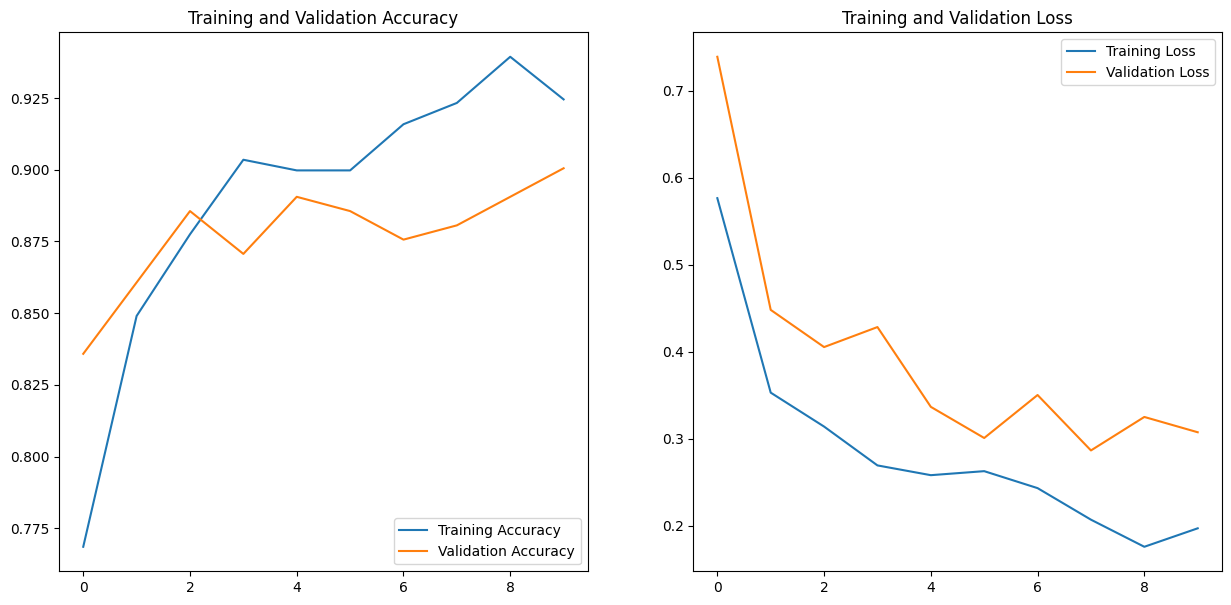

In [31]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']

val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

## Save the model

In [32]:
model_res.save("Model ResNet.keras")

# EfficientNet Model Implemantation

Import Base Model

In [33]:
from keras._tf_keras.keras.applications.efficientnet_v2 import EfficientNetV2B0
base_eff = EfficientNetV2B0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_eff.trainable = False

Add connected layers to base model

In [34]:
model_eff = Sequential()
resize_and_rescale
model_eff.add(base_eff)
model_eff.add(Flatten())
model_eff.add(Dense(256,activation='relu'))
model_eff.add(Dropout(0.5))
model_eff.add(BatchNormalization())
model_eff.add(Dense(num_classes,activation='sigmoid'))
model_eff.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 62720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │    16,056,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,977,426 (83.84 MB)

 Trainable params: 16,057,602 (61.25 MB)

 Non-trainable params: 5,919,824 (22.58 MB)

Compile the model

In [35]:
model_eff.compile(
    optimizer='adam',
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

Train the model

In [39]:
epochs = 5
history = model_eff.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds,
)

Epoch 1/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.9079 - loss: 0.2673 - val_accuracy: 0.8607 - val_loss: 0.3685
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.9039 - loss: 0.2351 - val_accuracy: 0.8557 - val_loss: 0.3312
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.9165 - loss: 0.2258 - val_accuracy: 0.8756 - val_loss: 0.3284
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.9185 - loss: 0.1959 - val_accuracy: 0.8756 - val_loss: 0.3170
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.9331 - loss: 0.1703 - val_accuracy: 0.8756 - val_loss: 0.3301


Evaluate the Model

In [40]:
model_eff.evaluate(test_ds)

11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 663ms/step - accuracy: 0.9268 - loss: 0.1933


[0.16316285729408264, 0.9346590638160706]

# Visualize training accuracy and losses

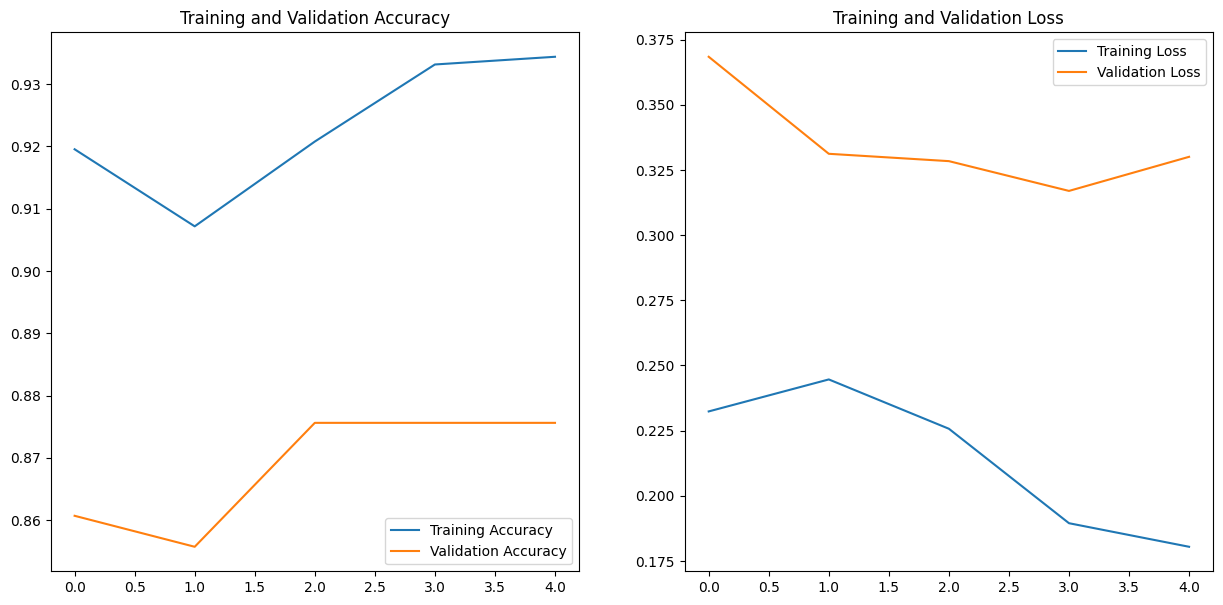

In [41]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']

val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

Save the Model

In [42]:
model_eff.save('Model EfficientNet.keras')